In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib import rc
from scipy.signal import convolve2d
from skimage.restoration import  richardson_lucy, unsupervised_wiener
from skimage.filters import window
from PIL import Image
from scipy.signal import wiener as wiener1
from skimage.filters import wiener as wiener2
from skimage.restoration import wiener as wiener3

rc({"text.usetex": True
    ,
    'family': 'serif', 'serif': ['Computer Modern'],
    })
plt.rcParams.update({'font.size': 10})

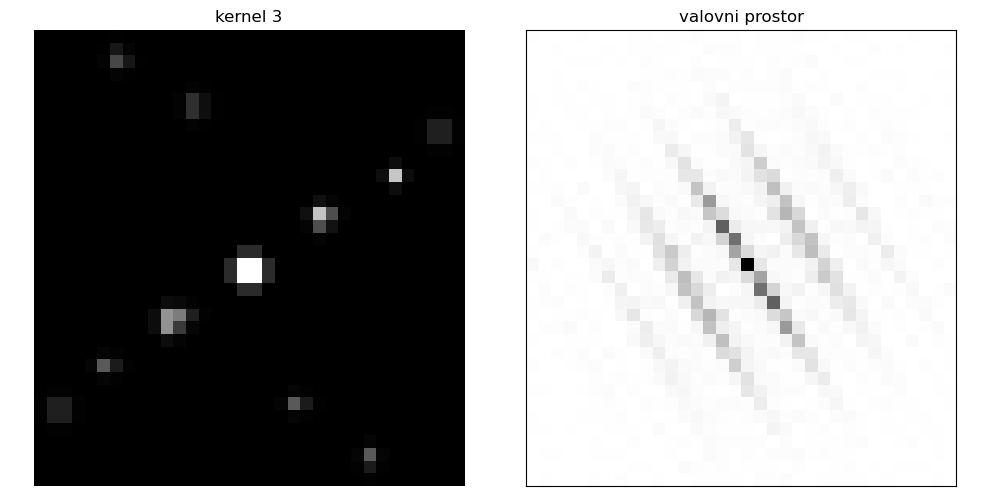

In [2]:
kernel1=np.loadtxt('podatki/lena_slike/kernel1.pgm',skiprows=3)
kernel2=np.loadtxt('podatki/lena_slike/kernel2.pgm',skiprows=3)
kernel3=np.loadtxt('podatki/lena_slike/kernel3.pgm',skiprows=3)
data = np.loadtxt('podatki/lena_slike/lena_k1_n0.pgm',skiprows=3)

kernel= kernel3
# kernel_data = np.loadtxt('podatki/lena_slike/'+kernel,skiprows=3)
# kernel_matrix = kernel_data[kernel_data != 0]
nonzero_rows = np.any(kernel != 0, axis=1)
nonzero_columns = np.any(kernel != 0, axis=0)
kernel_matrix = kernel[nonzero_rows][:, nonzero_columns]
kernel=kernel_matrix
kernel_fft = np.fft.fft2(kernel)
kernel_PSD = np.abs(kernel_fft)**2

plt.figure(figsize=(10,5))
gs = plt.GridSpec(1, 2, width_ratios=[1, 1])
plt.axis('off')
plt.subplot(gs[0])
plt.title('kernel 3')
plt.axis('off')
plt.imshow(kernel,cmap='gray')
plt.subplot(gs[1])
plt.title('valovni prostor')
plt.xticks([])
plt.yticks([])
plt.imshow(np.fft.fftshift(kernel_PSD), cmap='Grays')
plt.tight_layout()
#plt.savefig('slike/kernel3.pdf')
plt.show()

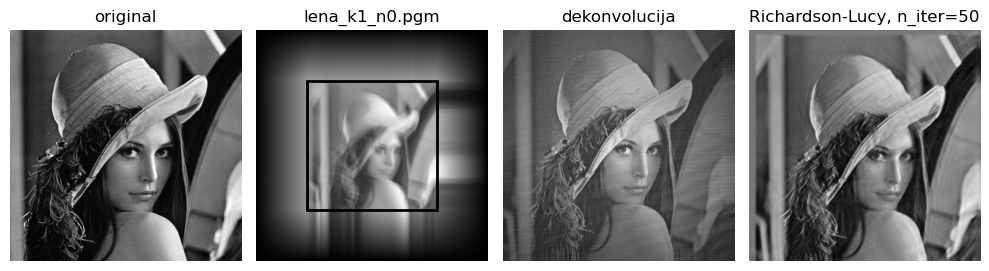

In [6]:
datoteka='lena_k1_n0.pgm'
kernel= kernel1
dim=512 #x, y
n_max=255 #to je belo
N_add=200 #število dadanih pikslov
n_iter=50 #R-L algoritem

data=np.loadtxt('podatki/lena_slike/'+datoteka,skiprows=3).reshape(dim,dim)
t = np.arange(0, dim)

data_resize=np.zeros(shape=(dim+2*N_add, dim+2*N_add))
data_resize[N_add:dim+N_add,N_add:dim+N_add] = data
kernel_resize = np.zeros(shape=(dim+2*N_add, dim+2*N_add))
kernel_resize[N_add:dim+N_add,N_add:dim+N_add] = kernel
# for i in range(dim): #dela le za N_add=dim!!!
#     for j in range(N_add):
#         data_resize[N_add+i,j] = data[i,j]#levo
#         data_resize[j,N_add+i] = data[j,i]#gor
#         data_resize[N_add+dim+i,N_add+j] = data[i,j]#dol
#         data_resize[N_add+j,N_add+dim+i] = data[j,i]#desno
# for i in range(N_add):
#     for j in range(N_add):
#         data_resize[N_add+dim+i,j] = data[i,j]#levo dol
#         data_resize[j,N_add+dim+i] = data[j,i]#desno gor
#         data_resize[i,j] = data[i,j]#levo gor
#         data_resize[N_add+dim+i,N_add+dim+j] = data[i,j]#desno dol
# tudi dodatek robnih pixlov/cele slike ne pomaga!!!
# data_resize[:N_add, N_add:-N_add] = data[0, :] #data[:N_add, :]#gor
# data_resize[-N_add:, N_add:-N_add] = data[-1, :] #data[-N_add:, :]#dol
# data_resize[N_add:-N_add, :N_add] = data[:, 0].reshape(-1, 1) #data[:, :N_add]#levo
# data_resize[N_add:-N_add, -N_add:] = data[:, -1].reshape(-1, 1) #data[:, -N_add:]#desno
# data_resize[:N_add, :N_add] = data[:N_add, :N_add]  # top-left corner
# data_resize[:N_add, -N_add:] = data[:N_add, -N_add:]  # top-right
# data_resize[-N_add:, :N_add] = data[-N_add:, :N_add]  # bottom-left
# data_resize[-N_add:, -N_add:] = data[-N_add:, -N_add:]  # bottom-right

data_resize = np.pad(data, ((N_add, N_add), (N_add, N_add)), mode='linear_ramp') #auto-padding!!

data = data_resize #razširitev slike
kernel = kernel_resize
okno = window('triang', data.shape)
signal_data=data*okno #okenske

signal_fft = np.fft.fft2(signal_data)
signal_freq = np.fft.fftfreq(dim)
signal_PSD = np.abs(signal_fft)**2

kernel_fft = np.fft.fft2(kernel)
kernel_PSD = np.abs(kernel_fft)**2
nonzero_rows = np.any(kernel != 0, axis=1)
nonzero_columns = np.any(kernel != 0, axis=0)
kernel_matrix = kernel[nonzero_rows][:, nonzero_columns]

deconvolved_fft = signal_fft / kernel_fft
deconvolved = np.fft.ifft2(deconvolved_fft)
deconvolved = np.fft.fftshift(deconvolved-np.min(deconvolved)) #remove negative
deconvolved = deconvolved/np.max(deconvolved)*255 #max is 255
deconvolved = deconvolved[N_add:-N_add, N_add:-N_add] #remove padding

psf=kernel_matrix #LSI (Linear Spatially Invariant) system?
deconvolved_lr = richardson_lucy(data_resize/255, psf, num_iter=n_iter) #iterativni algoritem
deconvolved_lr = deconvolved_lr-np.min(deconvolved_lr) #remove negative
deconvolved_lr = deconvolved_lr/np.max(deconvolved_lr)*255 #max is 255
deconvolved_lr = deconvolved_lr[N_add:-N_add, N_add:-N_add] #remove padding

plt.figure(figsize=(10,5))
gs = plt.GridSpec(nrows=1, ncols=4, width_ratios=[1, 1, 1, 1])
plt.subplot(gs[0])
plt.axis('off')
plt.title('original')
img = mpimg.imread('podatki/lena_slike/The-famous-Lena-image-often-used-as-an-example-in-image-processing.png')
imgplot = plt.imshow(img)

plt.subplot(gs[1])
plt.axis('off')
plt.title(datoteka)
plt.imshow(data,cmap='gray')
plt.gca().add_patch(plt.Rectangle((N_add, N_add), dim, dim, linewidth=2, edgecolor='k', facecolor='none'))

plt.subplot(gs[2])
plt.axis('off')
plt.title('dekonvolucija')
plt.imshow(deconvolved.real, cmap='gray')

plt.subplot(gs[3])
plt.axis('off')
plt.title('Richardson-Lucy, n_iter='+str(n_iter))
plt.imshow(deconvolved_lr, cmap='gray')
plt.tight_layout()
plt.show()

In [4]:
n=0
#deconvolved=deconvolved_lr
for i in range(dim):
    for j in range(dim):
        if deconvolved[i,j].real > 255 or deconvolved[i,j].real<0:
            n+=1
            print('neveljeavno: ', deconvolved[i,j].real, i,j, n)

In [5]:
def lena(n_kernel, šum, N_add, razširitev, okno):
    dim=512 #x, y
    data=np.loadtxt('podatki/lena_slike/lena_k'+str(n_kernel)+'_n'+str(šum)+'.pgm', skiprows=3).reshape(dim,dim)
    kernel =np.loadtxt('podatki/lena_slike/kernel'+str(n_kernel)+'.pgm', skiprows=3)

    kernel_resize = np.zeros(shape=(dim+2*N_add, dim+2*N_add))
    kernel_resize[N_add:dim+N_add,N_add:dim+N_add] = kernel
    data_resize = np.pad(data, ((N_add, N_add), (N_add, N_add)), mode=str(razširitev)) #auto-padding!!

    okno = window(str(okno), data_resize.shape)
    signal_data=data_resize*okno #okenske

    signal_fft = np.fft.fft2(signal_data)
    kernel_fft = np.fft.fft2(kernel_resize)

    deconvolved_fft = signal_fft / kernel_fft
    deconvolved = np.fft.ifft2(deconvolved_fft)
    deconvolved = np.fft.fftshift(deconvolved-np.min(deconvolved)) #remove negative
    deconvolved = deconvolved/np.max(deconvolved)*255 #max is 255
    deconvolved = deconvolved[N_add:-N_add, N_add:-N_add] #remove padding
    return data_resize, deconvolved
def lena_lr(n_kernel, šum, N_add, razširitev, n_iter):
    dim=512 #x, y
    data=np.loadtxt('podatki/lena_slike/lena_k'+str(n_kernel)+'_n'+str(šum)+'.pgm', skiprows=3).reshape(dim,dim)
    kernel =np.loadtxt('podatki/lena_slike/kernel'+str(n_kernel)+'.pgm', skiprows=3)

    data_resize = np.pad(data, ((N_add, N_add), (N_add, N_add)), mode=str(razširitev)) #auto-padding!!
    nonzero_rows = np.any(kernel != 0, axis=1)
    nonzero_columns = np.any(kernel != 0, axis=0)
    kernel_matrix = kernel[nonzero_rows][:, nonzero_columns]
    
    deconvolved_lr = richardson_lucy(data_resize/255, kernel_matrix, num_iter=n_iter) #iterativni algoritem
    deconvolved_lr = deconvolved_lr-np.min(deconvolved_lr) #remove negative
    deconvolved_lr = deconvolved_lr/np.max(deconvolved_lr)*255 #max is 255
    deconvolved_lr = deconvolved_lr[N_add:-N_add, N_add:-N_add] #remove padding
    return data_resize, deconvolved_lr
def plot_row(n_kernel,šum,razširitev,N_add,vrstica):
    i=vrstica*6
    okno = 'boxcar'
    data, deconvolved = lena(n_kernel,šum,N_add,razširitev,okno)
    plt.subplot(gs[i])
    plt.axis('off')
    plt.title('razširitev: '+razširitev+'\n dodano: '+str(N_add))
    plt.imshow(data,cmap='gray')
    plt.gca().add_patch(plt.Rectangle((N_add, N_add), dim, dim, linewidth=2, edgecolor='k', facecolor='none'))

    i+=1
    plt.subplot(gs[i])
    plt.axis('off')
    plt.title('dekonvolucija \n okno: '+okno)
    plt.imshow(deconvolved.real, cmap='gray')

    i+=1
    okno = 'triang'
    data, deconvolved = lena(n_kernel,šum,N_add,razširitev,okno)
    plt.subplot(gs[i])
    plt.axis('off')
    plt.title('dekonvolucija \n okno: '+okno)
    plt.imshow(deconvolved.real, cmap='gray')

    i+=1
    okno = 'blackman'
    data, deconvolved = lena(n_kernel,šum,N_add,razširitev,okno)
    plt.subplot(gs[i])
    plt.axis('off')
    plt.title('dekonvolucija \n okno: '+okno)
    plt.imshow(deconvolved.real, cmap='gray')

    i+=1
    okno = 'hann'
    data, deconvolved = lena(n_kernel,šum,N_add,razširitev,okno)
    plt.subplot(gs[i])
    plt.axis('off')
    plt.title('dekonvolucija \n okno: '+okno)
    plt.imshow(deconvolved.real, cmap='gray')

    i+=1
    okno = 'barthann'
    data, deconvolved = lena(n_kernel,šum,N_add,razširitev,okno)
    plt.subplot(gs[i])
    plt.axis('off')
    plt.title('dekonvolucija \n okno: '+okno)
    plt.imshow(deconvolved.real, cmap='gray')

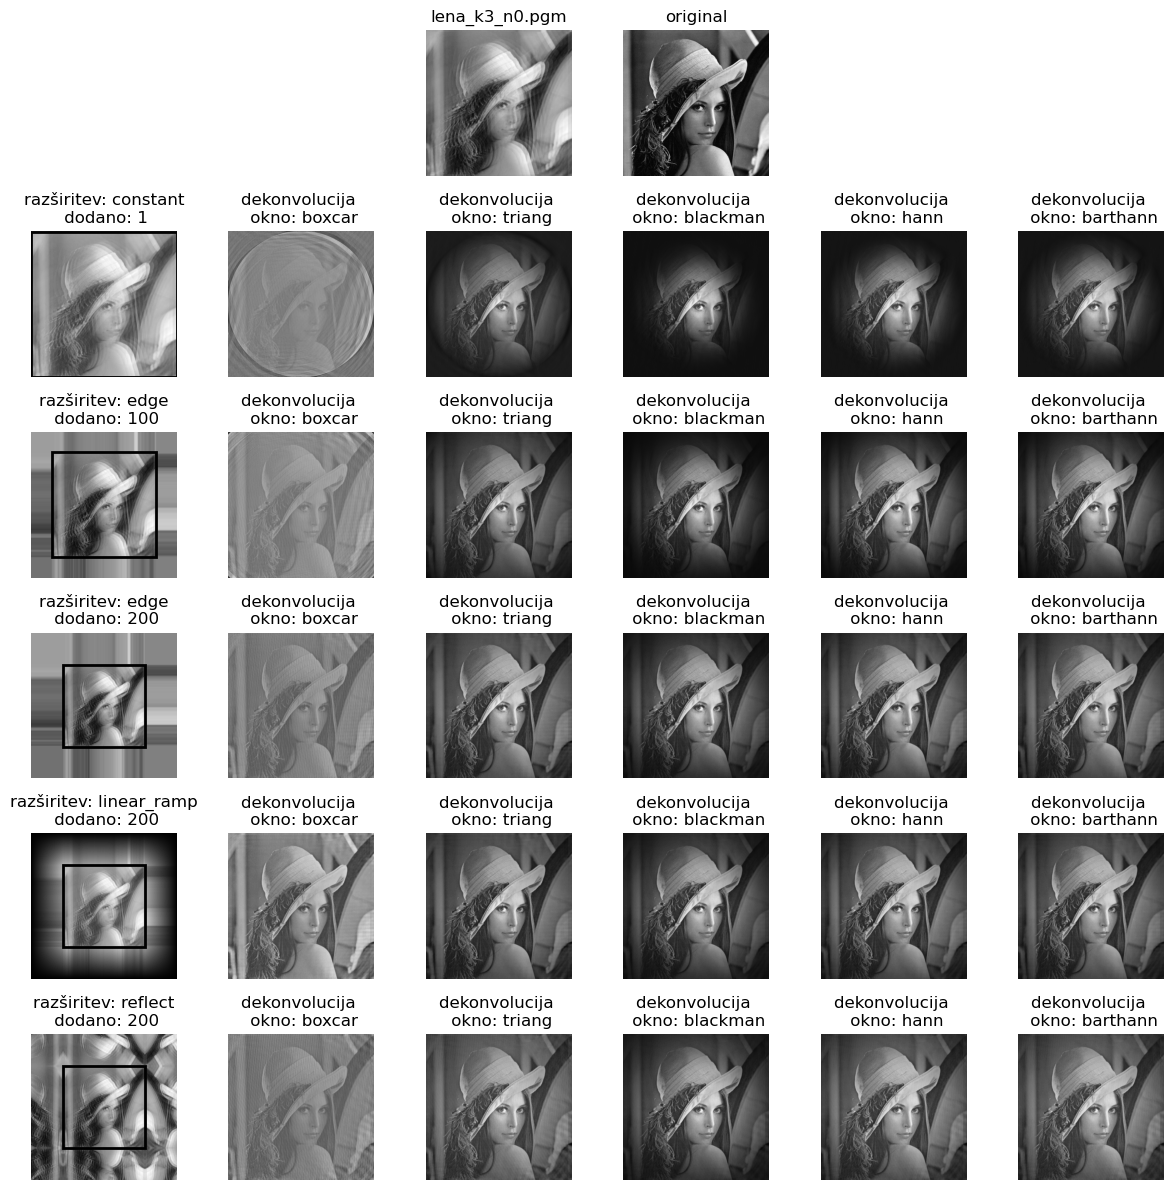

In [8]:
#podatki
n_kernel = 3
šum = 0
dim=512 #fixed

plt.figure(figsize=(12,12))
gs = plt.GridSpec(nrows=6, ncols=6)

plt.subplot(gs[2])
plt.axis('off')
plt.title('lena_k'+str(n_kernel)+'_n'+str(šum)+'.pgm')
img = mpimg.imread('podatki/lena_slike/lena_k'+str(n_kernel)+'_n'+str(šum)+'.pgm')
imgplot = plt.imshow(img, cmap='gray')

plt.subplot(gs[3])
plt.axis('off')
plt.title('original')
img = mpimg.imread('podatki/lena_slike/The-famous-Lena-image-often-used-as-an-example-in-image-processing.png')
imgplot = plt.imshow(img)

vrstica=1
razširitev = 'constant'
N_add = 1
plot_row(n_kernel,šum,razširitev,N_add,vrstica)

vrstica=2
razširitev = 'edge'
N_add = 100
plot_row(n_kernel,šum,razširitev,N_add,vrstica)

vrstica=3
razširitev = 'edge'
N_add = 200
plot_row(n_kernel,šum,razširitev,N_add,vrstica)

vrstica=4
razširitev = 'linear_ramp'
N_add = 200
plot_row(n_kernel,šum,razširitev,N_add,vrstica)

vrstica=5
razširitev = 'reflect'
N_add = 200
plot_row(n_kernel,šum,razširitev,N_add,vrstica)

# vrstica=6
# razširitev = 'symmetric' #isto reflect
# N_add = 100
# plot_row(n_kernel,šum,razširitev,N_add,vrstica)

plt.tight_layout()
#plt.savefig('slike/kernel1_dekonv_test.pdf')
plt.show()

### razširitev
mode : str or function, optional
    One of the following string values or a user supplied function.

    'constant' (default)
        Pads with a constant value.
    'edge'
        Pads with the edge values of array.
    'linear_ramp'
        Pads with the linear ramp between end_value and the array edge value.
    'maximum'
        Pads with the maximum value of all or part of the vector along each axis.
    'mean'
        Pads with the mean value of all or part of the vector along each axis.
    'median'
        Pads with the median value of all or part of the vector along each axis.
    'minimum'
        Pads with the minimum value of all or part of the vector along each axis.
    'reflect'
        Pads with the reflection of the vector mirrored on the first and last values of the vector along each axis.
    'symmetric'
        Pads with the reflection of the vector mirrored along the edge of the array.
    'wrap'
        Pads with the wrap of the vector along the axis. The first values are used to pad the end and the end values are used to pad the beginning.
    'empty'
        Pads with undefined values.

### okno
Window types:

boxcar
triang
blackman
hamming
hann
bartlett
flattop
parzen
bohman
blackmanharris
nuttall
barthann

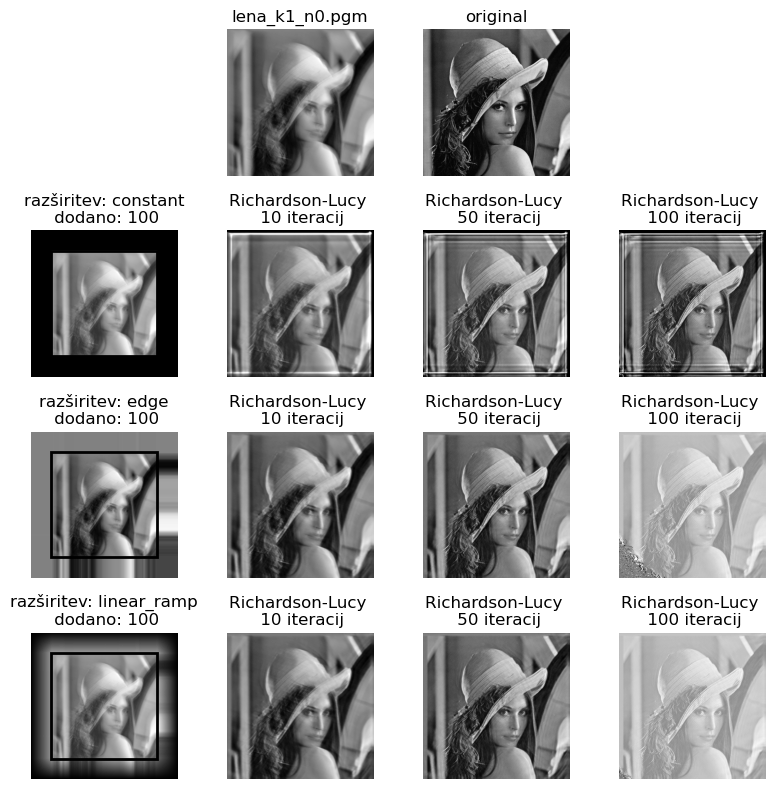

In [290]:
#podatki
n_kernel = 1
šum = 0
dim=512 #fixed

plt.figure(figsize=(8,8))
gs = plt.GridSpec(nrows=4, ncols=4)

plt.subplot(gs[1])
plt.axis('off')
plt.title('lena_k'+str(n_kernel)+'_n'+str(šum)+'.pgm')
img = mpimg.imread('podatki/lena_slike/lena_k'+str(n_kernel)+'_n'+str(šum)+'.pgm')
imgplot = plt.imshow(img, cmap='gray')

plt.subplot(gs[2])
plt.axis('off')
plt.title('original')
img = mpimg.imread('podatki/lena_slike/The-famous-Lena-image-often-used-as-an-example-in-image-processing.png')
imgplot = plt.imshow(img)

##############################
n_iter = 10
razširitev = 'constant'
N_add = 100
data, deconvolved_lr = lena_lr(n_kernel,šum,N_add,razširitev,n_iter)

plt.subplot(gs[4])
plt.axis('off')
plt.title('razširitev: '+razširitev+'\n dodano: '+str(N_add))
plt.imshow(data,cmap='gray')
plt.gca().add_patch(plt.Rectangle((N_add, N_add), dim, dim, linewidth=2, edgecolor='k', facecolor='none'))

plt.subplot(gs[5])
plt.axis('off')
plt.title('Richardson-Lucy \n '+str(n_iter)+ ' iteracij')
plt.imshow(deconvolved_lr, cmap='gray')

n_iter = 50
data, deconvolved_lr = lena_lr(n_kernel,šum,N_add,razširitev,n_iter)
plt.subplot(gs[6])
plt.axis('off')
plt.title('Richardson-Lucy \n '+str(n_iter)+ ' iteracij')
plt.imshow(deconvolved_lr, cmap='gray')

n_iter = 100
data, deconvolved_lr = lena_lr(n_kernel,šum,N_add,razširitev,n_iter)
plt.subplot(gs[7])
plt.axis('off')
plt.title('Richardson-Lucy \n '+str(n_iter)+ ' iteracij')
plt.imshow(deconvolved_lr, cmap='gray')

############################
n_iter = 10
razširitev = 'edge'
N_add = 100
data, deconvolved_lr = lena_lr(n_kernel,šum,N_add,razširitev,n_iter)

plt.subplot(gs[8])
plt.axis('off')
plt.title('razširitev: '+razširitev+'\n dodano: '+str(N_add))
plt.imshow(data,cmap='gray')
plt.gca().add_patch(plt.Rectangle((N_add, N_add), dim, dim, linewidth=2, edgecolor='k', facecolor='none'))

plt.subplot(gs[9])
plt.axis('off')
plt.title('Richardson-Lucy \n '+str(n_iter)+ ' iteracij')
plt.imshow(deconvolved_lr, cmap='gray')

n_iter = 50
data, deconvolved_lr = lena_lr(n_kernel,šum,N_add,razširitev,n_iter)
plt.subplot(gs[10])
plt.axis('off')
plt.title('Richardson-Lucy \n '+str(n_iter)+ ' iteracij')
plt.imshow(deconvolved_lr, cmap='gray')

n_iter = 100
data, deconvolved_lr = lena_lr(n_kernel,šum,N_add,razširitev,n_iter)
plt.subplot(gs[11])
plt.axis('off')
plt.title('Richardson-Lucy \n '+str(n_iter)+ ' iteracij')
plt.imshow(deconvolved_lr, cmap='gray')

############################
n_iter = 10
razširitev = 'linear_ramp'
N_add = 100
data, deconvolved_lr = lena_lr(n_kernel,šum,N_add,razširitev,n_iter)

plt.subplot(gs[12])
plt.axis('off')
plt.title('razširitev: '+razširitev+'\n dodano: '+str(N_add))
plt.imshow(data,cmap='gray')
plt.gca().add_patch(plt.Rectangle((N_add, N_add), dim, dim, linewidth=2, edgecolor='k', facecolor='none'))

plt.subplot(gs[13])
plt.axis('off')
plt.title('Richardson-Lucy \n '+str(n_iter)+ ' iteracij')
plt.imshow(deconvolved_lr, cmap='gray')

n_iter = 50
data, deconvolved_lr = lena_lr(n_kernel,šum,N_add,razširitev,n_iter)
plt.subplot(gs[14])
plt.axis('off')
plt.title('Richardson-Lucy \n '+str(n_iter)+ ' iteracij')
plt.imshow(deconvolved_lr, cmap='gray')

n_iter = 100
data, deconvolved_lr = lena_lr(n_kernel,šum,N_add,razširitev,n_iter)
plt.subplot(gs[15])
plt.axis('off')
plt.title('Richardson-Lucy \n '+str(n_iter)+ ' iteracij')
plt.imshow(deconvolved_lr, cmap='gray')

plt.tight_layout()
#plt.savefig('slike/kernel1_dekonv_LR.pdf')
plt.show()

# napaka

In [219]:
#podatki slike
n_kernel = 1
šum = 0
dim=512 #fixed

slika = mpimg.imread('podatki/lena_slike/lena_k'+str(n_kernel)+'_n'+str(šum)+'.pgm')
im = Image.open('podatki/lena_slike/The-famous-Lena-image-often-used-as-an-example-in-image-processing.png')
ref = np.array(im.convert('L')) #RGBA -> grayscale

#parametri
razširitev = 'linear_ramp'
N_add = 200
okno = 'triang'
n_iter = 50

data, deconvolved = lena(n_kernel, šum, N_add, razširitev, okno)
_, deconvolved_lr = lena_lr(n_kernel, šum, N_add, razširitev, n_iter)
napaka = np.sum(np.abs(ref-slika))
napaka_deconv = np.sum(np.abs(ref-deconvolved))
napaka_deconv_lr = np.sum(np.abs(ref-deconvolved_lr))
relative = napaka_deconv/napaka*100 #manj je, bolje je!
relative_lr = napaka_deconv_lr/napaka*100
relative, relative_lr

(28.501316164441214, 63.26406742064277)

In [220]:
def napaka_slike(n_kernel, šum, N_add, razširitev, okno):
    slika = mpimg.imread('podatki/lena_slike/lena_k'+str(n_kernel)+'_n'+str(šum)+'.pgm')
    im = Image.open('podatki/lena_slike/The-famous-Lena-image-often-used-as-an-example-in-image-processing.png')
    ref = np.array(im.convert('L')) #RGBA -> grayscale

    data, deconvolved = lena(n_kernel, šum, N_add, razširitev, okno)
    napaka = np.sum(np.abs(ref-slika))
    napaka_deconv = np.sum(np.abs(ref-deconvolved))
    relative = napaka_deconv/napaka*100 #manj je, bolje je!
    return relative
def napaka_slike_lr(n_kernel, šum, N_add, razširitev, n_iter):
    slika = mpimg.imread('podatki/lena_slike/lena_k'+str(n_kernel)+'_n'+str(šum)+'.pgm')
    im = Image.open('podatki/lena_slike/The-famous-Lena-image-often-used-as-an-example-in-image-processing.png')
    ref = np.array(im.convert('L')) #RGBA -> grayscale

    data, deconvolved = lena_lr(n_kernel, šum, N_add, razširitev, n_iter)
    napaka = np.sum(np.abs(ref-slika))
    napaka_deconv = np.sum(np.abs(ref-deconvolved))
    relative = napaka_deconv/napaka*100 #manj je, bolje je!
    return relative

In [235]:
n_kernel = 1
šum = 0
dim = 512
razširitev='linear_ramp'
okna = ['boxcar', 'triang', 'blackman', 'hann', 'barthann']
N_range = np.arange(1, dim, step=50)

res_okna = {}
for okno in okna:
    r=[]
    for N_add in N_range:
        err = napaka_slike(n_kernel, šum, N_add,razširitev, okno)
        r.append(err)
    res_okna[okno] = r

In [236]:
razširitve = ['constant','edge', 'reflect', 'linear_ramp']
okno = 'triang'
N_range = np.arange(1, dim, step=50)

res_razšir = {}
for razširitev in razširitve:
    r=[]
    for N_add in N_range:
        err = napaka_slike(n_kernel, šum, N_add,razširitev, okno)
        r.append(err)
    res_razšir[razširitev] = r

In [237]:
n_iter=10
razširitev='linear_ramp'
okna = ['boxcar', 'triang', 'blackman', 'hann', 'barthann']
#iteracije = np.arange(1, 50, step=5)
N_range_lr = np.arange(1, dim//2, step=50)

res_okna_lr = {}
for okno in okna:
    r=[]
    for N_add in N_range_lr:
        err = napaka_slike_lr(n_kernel, šum, N_add,razširitev, n_iter)
        r.append(err)
    res_okna_lr[okno] = r

In [238]:
n_iter = 10
razširitve = ['constant','edge', 'reflect', 'linear_ramp']
okno = 'triang'
#iteracije = np.arange(1, 50, step=5)
N_range_lr = np.arange(1, dim//2, step=50)

res_razšir_lr = {}
for razširitev in razširitve:
    r=[]
    for N_add in N_range_lr:
        err = napaka_slike_lr(n_kernel, šum, N_add,razširitev, n_iter)
        r.append(err)
    res_razšir_lr[razširitev] = r

In [239]:
razširitve = ['constant','edge', 'reflect', 'linear_ramp']
okno = 'triang'
N_add=100
#iteracije = np.arange(1, 150, step=25)
iteracije = np.geomspace(2,200,10,dtype=int)

res_iter_lr = {}
for razširitev in razširitve:
    r=[]
    for n_iter in iteracije:
        err = napaka_slike_lr(n_kernel, šum, N_add,razširitev, n_iter)
        r.append(err)
    res_iter_lr[razširitev] = r

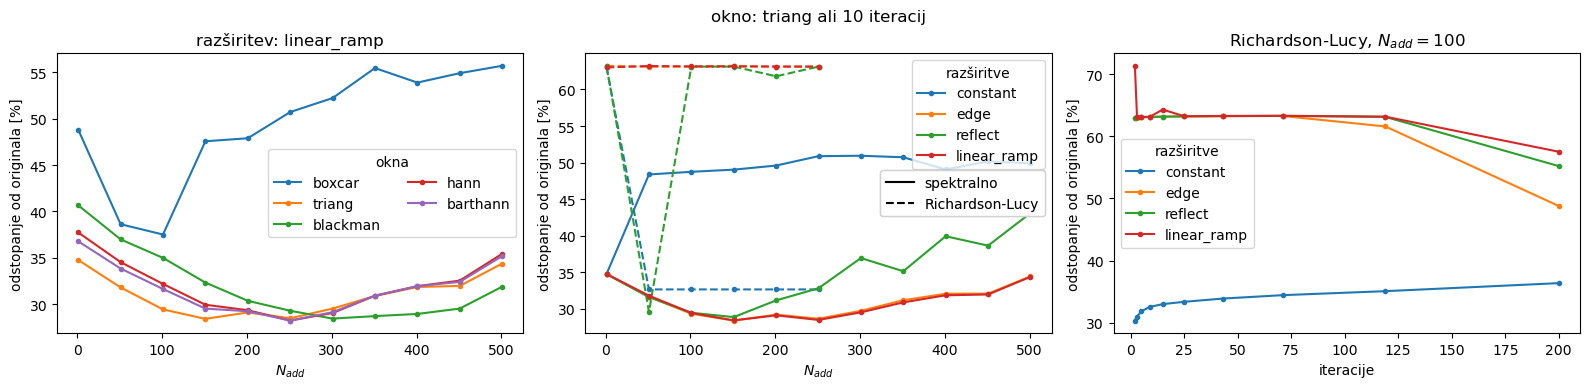

In [249]:
plt.figure(figsize=(16,4))
gs = plt.GridSpec(nrows=1, ncols=3)

ax1=plt.subplot(gs[0])
ax1.set_title('razširitev: linear_ramp')
ax1.set_xlabel('$N_{add}$')
ax1.set_ylabel('odstopanje od originala [%]')

# ax2 = ax1.twiny()
# ax2.set_xlim(ax1.get_xlim())
# rescale_factor = len(N_range) / len(iteracije)
# ticks = [int(i * rescale_factor) for i in iteracije]
# ax2.set_xticks(ticks)
# ax2.set_xticklabels(iteracije)
# ax2.set_xlabel('iteracije')

for okno in okna:
    color = color = ax1._get_lines.get_next_color()
    ax1.plot(N_range, res_okna[okno], '.-',label=okno, color=color)
    #ax2.plot(iteracije, res_okna_lr[okno], '.--', color=color)
ax1.legend(title='okna',loc='best', ncol=2)
# legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='k', linestyle='-', label='spektralno'),
#                                          plt.Line2D([], [], color='k', linestyle='--', label='Richardson-Lucy')],
#                                 loc='center', ncol=1, bbox_to_anchor=(0.6,0.5))
# plt.gca().add_artist(legend_line_styles)

###############
ax1=plt.subplot(gs[1])
ax1.set_title('okno: triang ali 10 iteracij')
ax1.set_xlabel('$N_{add}$')
ax1.set_ylabel('odstopanje od originala [%]')

ax2 = ax1.twiny()
ax2.axis('off')
# ax2.set_xlim(ax1.get_xlim())
# rescale_factor = len(N_range) / len(iteracije)
# ticks = [int(i * rescale_factor) for i in iteracije]
# ax2.set_xticks(ticks)
# ax2.set_xticklabels(iteracije)
# ax2.set_xlabel('iteracije Richardson-Lucy algoritma')

for razširitev in razširitve:
    color = color = ax1._get_lines.get_next_color()
    ax1.plot(N_range, res_razšir[razširitev], '.-',label=razširitev, color=color)
    ax1.plot(N_range_lr, res_razšir_lr[razširitev], '.--', color=color)
leg1=ax1.legend(title='razširitve', loc='best',ncol=1)
legend_line_styles = ax2.legend(handles=[plt.Line2D([], [], color='k', linestyle='-', label='spektralno'),
                                         plt.Line2D([], [], color='k', linestyle='--', label='Richardson-Lucy')],
                                loc='center right', ncol=1)
plt.gca().add_artist(legend_line_styles)

###########################
ax1=plt.subplot(gs[2])
ax1.set_title('Richardson-Lucy, $N_{add}=100$')
ax1.set_xlabel('iteracije')
ax1.set_ylabel('odstopanje od originala [%]')

for razširitev in razširitve:
    color = color = ax1._get_lines.get_next_color()
    ax1.plot(iteracije, res_iter_lr[razširitev], '.-',label=razširitev, color=color)
ax1.legend(title='razširitve')

plt.tight_layout()
#plt.savefig('slike/napaka_kernel'+str(n_kernel)+'.pdf') #pazi kateri n_kernel je zapisan
plt.show()
#100% odstopanje pomeni izhodiščno sliko!!

# ostale slike

In [227]:
def lena_primer(n_kernel, šum, N_add, razširitev, okno, n_iter, vrstica):
    data, deconvolved = lena(n_kernel, šum, N_add, razširitev, okno)
    data, deconvolved_lr = lena_lr(n_kernel, šum, N_add, razširitev, n_iter)
    slika = mpimg.imread('podatki/lena_slike/lena_k'+str(n_kernel)+'_n'+str(šum)+'.pgm') #isto!?
    
    im = Image.open('podatki/lena_slike/The-famous-Lena-image-often-used-as-an-example-in-image-processing.png')
    ref = np.array(im.convert('L')) #RGBA -> grayscale

    napaka = np.sum(np.abs(ref-slika))
    napaka_deconv = np.sum(np.abs(ref-deconvolved))
    relative = napaka_deconv/napaka*100
    napaka_deconv = np.sum(np.abs(ref-deconvolved_lr))
    relative_lr = napaka_deconv/napaka*100

    dim=512 #x, y
    i=vrstica*3

    plt.subplot(gs[i])
    plt.axis('off')
    plt.title('lena_k'+n_kernel+'_n'+šum+'.pgm \n'+razširitev+', $N_{add}=$'+str(N_add))
    plt.imshow(data,cmap='gray')
    plt.gca().add_patch(plt.Rectangle((N_add, N_add), dim, dim, linewidth=2, edgecolor='k', facecolor='none'))
    i+=1

    plt.subplot(gs[i])
    plt.axis('off')
    plt.title('dekonvolucija \n okno: '+okno+'\n ujemanje: '+str(round(100-relative))+'%')
    plt.imshow(deconvolved.real, cmap='gray')
    i+=1

    plt.subplot(gs[i])
    plt.axis('off')
    plt.title('Richardson-Lucy \n n_iter='+str(n_iter)+'\n ujemanje: '+str(round(100-relative_lr))+'%')
    plt.imshow(deconvolved_lr, cmap='gray')

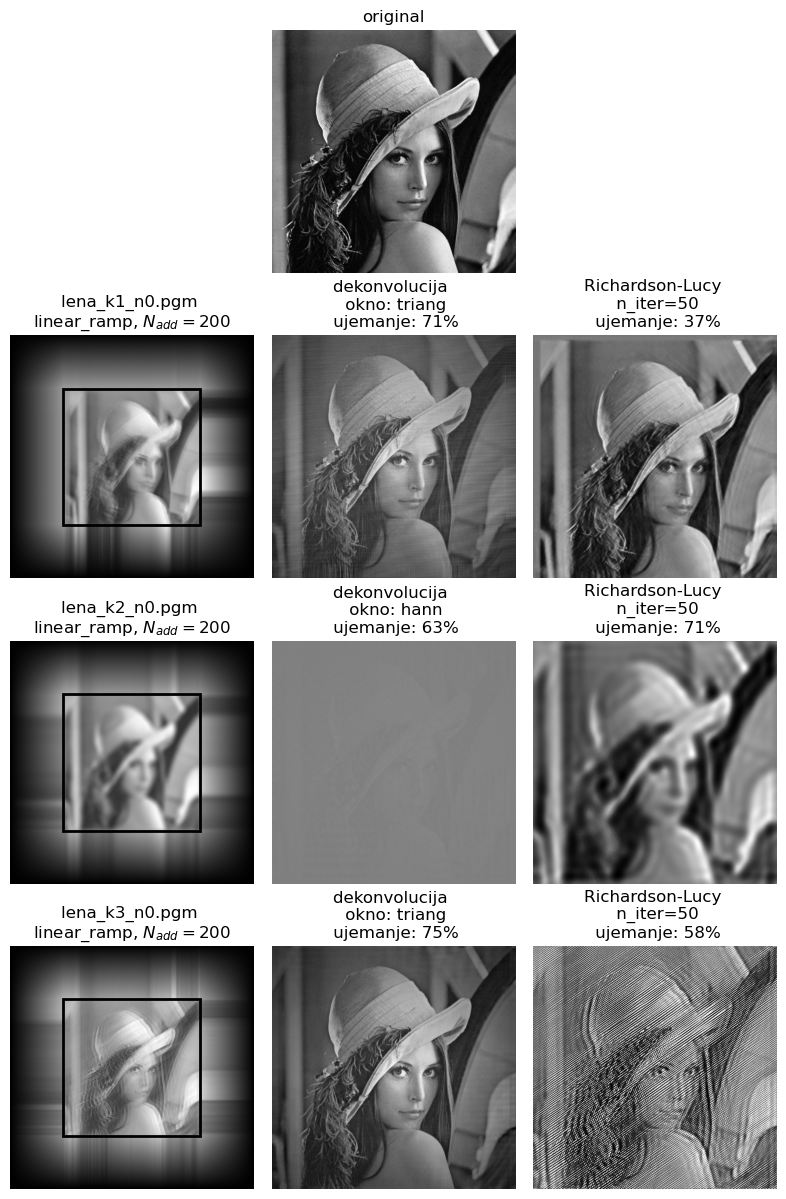

In [250]:
n_kernel = '1'
šum = '0'
N_add= 200 #število dadanih pikslov
razširitev = 'linear_ramp'
okno = 'triang'
n_iter=50 #R-L algoritem

plt.figure(figsize=(8,12))
gs = plt.GridSpec(nrows=4, ncols=3)

plt.subplot(gs[1])
plt.axis('off')
plt.title('original')
img = mpimg.imread('podatki/lena_slike/The-famous-Lena-image-often-used-as-an-example-in-image-processing.png')
plt.imshow(img)

vrstica=1
lena_primer(n_kernel, šum, N_add, razširitev, okno, n_iter, vrstica)

n_kernel = '2'
vrstica=2
#n_iter=100
okno = 'hann'
lena_primer(n_kernel, šum, N_add, razširitev, okno, n_iter, vrstica)

n_kernel = '3'
vrstica=3
n_iter=50
okno = 'triang'
lena_primer(n_kernel, šum, N_add, razširitev, okno, n_iter, vrstica)

plt.tight_layout()
#plt.savefig('slike/dekonv_vsa_jedra.pdf')

# wiener

In [293]:
datoteka='lena_k1_nx.pgm'
kernel= kernel1
N_add=200 #število dadanih pikslov
n_iter=50 #R-L algoritem
dim=512 #x, y

data=np.loadtxt('podatki/lena_slike/'+datoteka,skiprows=3).reshape(dim,dim)
t = np.arange(0, dim)

kernel_resize = np.zeros(shape=(dim+2*N_add, dim+2*N_add))
kernel_resize[N_add:dim+N_add,N_add:dim+N_add] = kernel
data_resize = np.pad(data, ((N_add, N_add), (N_add, N_add)), mode='linear_ramp') #auto-padding!!

data = data_resize #razširitev slike
kernel = kernel_resize
okno = window('triang', data.shape)
signal_data=data*okno #okenske

kernel_fft = np.fft.fft2(kernel)
signal_fft = np.fft.fft2(signal_data)
signal_freq = np.fft.fftfreq(dim)
signal_PSD = np.abs(signal_fft)**2

deconvolved_fft = signal_fft / kernel_fft
deconvolved = np.fft.ifft2(deconvolved_fft)
deconvolved = np.fft.fftshift(deconvolved-np.min(deconvolved)) #remove negative
deconvolved = deconvolved/np.max(deconvolved)*255 #max is 255
deconvolved = deconvolved[N_add:-N_add, N_add:-N_add] #remove padding

# deconvolved_fft = wiener1(deconvolved_fft) #scipy
# deconvolved_w = np.fft.ifft2(deconvolved_fft)
# deconvolved_w = np.fft.fftshift(deconvolved_w-np.min(deconvolved_w))
# deconvolved_w = deconvolved_w/np.max(deconvolved_w)*255
# deconvolved_w = deconvolved_w[N_add:-N_add, N_add:-N_add]

# deconvolved_fft = wiener2(deconvolved_fft) #skimage.filters #TODO: preizkusi v nalogi 10.2
# deconvolved_w = np.fft.ifft2(deconvolved_fft)
# deconvolved_w = np.fft.fftshift(deconvolved_w-np.min(deconvolved_w))
# deconvolved_w = deconvolved_w/np.max(deconvolved_w)*255 
# deconvolved_w = deconvolved_w[N_add:-N_add, N_add:-N_add]

noise = 10**6 #kernel1 in 2
#noise = 1 #kernel3
deconvolved_w = wiener3(signal_data, psf=kernel, balance=noise) #skimage.restoration deluje, a rabi velik 'balance'; izvede tudi dekonvolucijo
deconvolved_w = deconvolved_w-np.min(deconvolved_w)
deconvolved_w = deconvolved_w/np.max(deconvolved_w)*255
deconvolved_w1 = deconvolved_w[N_add:-N_add, N_add:-N_add]

deconvolved_w,_ = unsupervised_wiener(signal_data, kernel) #deluje avtomatsko!
deconvolved_w = deconvolved_w-np.min(deconvolved_w)
deconvolved_w = deconvolved_w/np.max(deconvolved_w)*255
deconvolved_w2 = deconvolved_w[N_add:-N_add, N_add:-N_add]

nonzero_rows = np.any(kernel != 0, axis=1)
nonzero_columns = np.any(kernel != 0, axis=0)
kernel_matrix = kernel[nonzero_rows][:, nonzero_columns]
psf=kernel_matrix #LSI (Linear Spatially Invariant) system
deconvolved_lr = richardson_lucy(data_resize/255, psf, num_iter=n_iter) #iterativni algoritem
deconvolved_lr = deconvolved_lr-np.min(deconvolved_lr) #remove negative
deconvolved_lr = deconvolved_lr/np.max(deconvolved_lr)*255 #max is 255
deconvolved_lr = deconvolved_lr[N_add:-N_add, N_add:-N_add] #remove padding

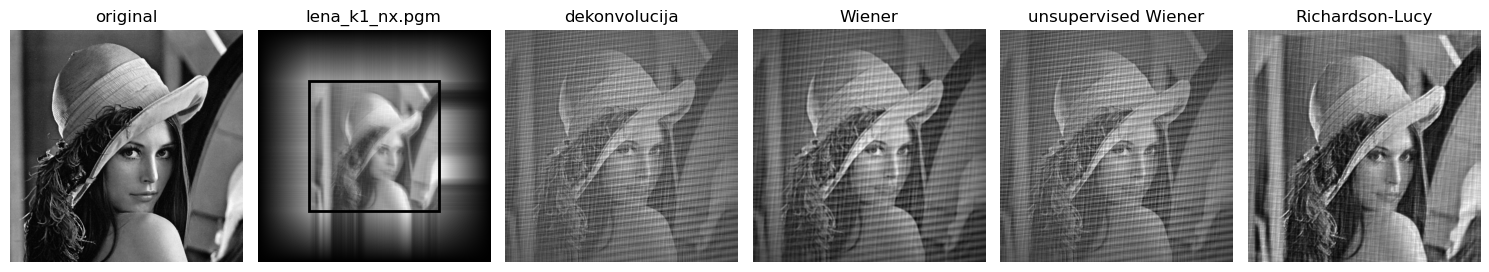

In [294]:
plt.figure(figsize=(15,5))
gs = plt.GridSpec(nrows=1, ncols=6)
plt.subplot(gs[0])
plt.axis('off')
plt.title('original')
img = mpimg.imread('podatki/lena_slike/The-famous-Lena-image-often-used-as-an-example-in-image-processing.png')
imgplot = plt.imshow(img)

plt.subplot(gs[1])
plt.axis('off')
plt.title(datoteka)
plt.imshow(data,cmap='gray')
plt.gca().add_patch(plt.Rectangle((N_add, N_add), dim, dim, linewidth=2, edgecolor='k', facecolor='none'))

plt.subplot(gs[2])
plt.axis('off')
plt.title('dekonvolucija')
plt.imshow(deconvolved.real, cmap='gray')

plt.subplot(gs[3])
plt.axis('off')
plt.title('Wiener')
plt.imshow(deconvolved_w1.real, cmap='gray')

plt.subplot(gs[4])
plt.axis('off')
plt.title('unsupervised Wiener')
plt.imshow(deconvolved_w2.real, cmap='gray')

plt.subplot(gs[5])
plt.axis('off')
plt.title('Richardson-Lucy')
plt.imshow(deconvolved_lr, cmap='gray')

plt.tight_layout()
plt.show()

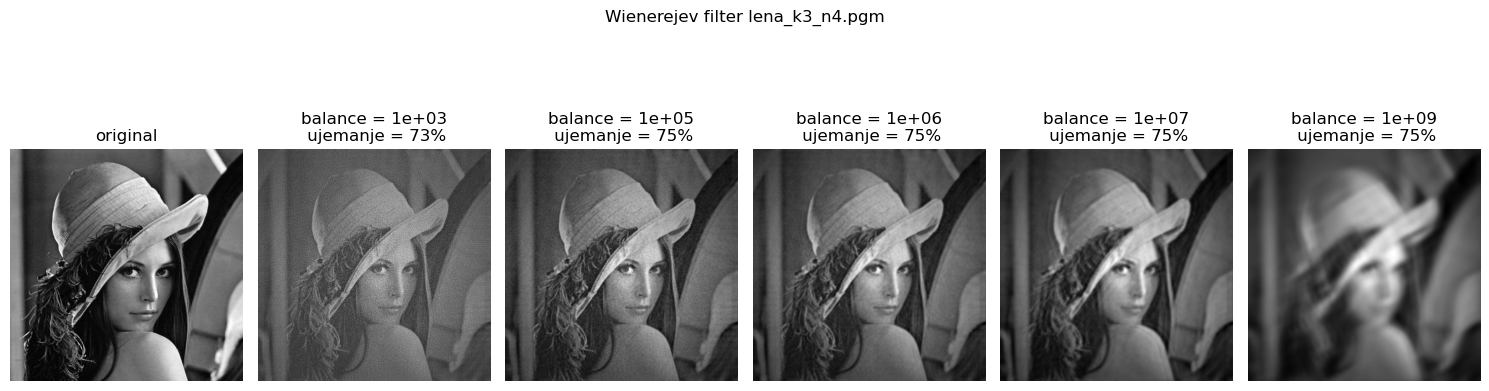

In [286]:
datoteka='lena_k3_n4.pgm'
kernel= kernel3
N_add=200 #število dadanih pikslov
n_iter=50 #R-L algoritem
noise = 100000
dim=512 #x, y
data = mpimg.imread('podatki/lena_slike/'+datoteka) #isto!?

def test_wiener(data, kernel, noise, ref):
    napaka = np.sum(np.abs(ref-data))
    kernel_resize = np.zeros(shape=(dim+2*N_add, dim+2*N_add))
    kernel_resize[N_add:dim+N_add,N_add:dim+N_add] = kernel
    data_resize = np.pad(data, ((N_add, N_add), (N_add, N_add)), mode='linear_ramp') #auto-padding!!

    data = data_resize #razširitev slike
    kernel = kernel_resize
    okno = window('triang', data.shape)
    signal_data=data*okno #okenske

    deconvolved_w = wiener3(signal_data, psf=kernel, balance=noise) #skimage.restoration deluje, a rabi velik 'balance'; izvede tudi dekonvolucijo
    deconvolved_w = deconvolved_w-np.min(deconvolved_w)
    deconvolved_w = deconvolved_w/np.max(deconvolved_w)*255
    deconvolved = deconvolved_w[N_add:-N_add, N_add:-N_add]

    napaka_deconv = np.sum(np.abs(ref-deconvolved))
    relative = napaka_deconv/napaka*100
    return deconvolved, relative

fig=plt.figure(figsize=(15,5))
fig.suptitle('Wienerejev filter '+datoteka)
gs = plt.GridSpec(nrows=1, ncols=6)
plt.subplot(gs[0])
plt.axis('off')
plt.title('original')
img = Image.open('podatki/lena_slike/The-famous-Lena-image-often-used-as-an-example-in-image-processing.png')
ref = np.array(img.convert('L')) #RGBA -> grayscale
imgplot = plt.imshow(ref, cmap='gray')

noise = 10**3
# noise = 10**4
deconvolved,err = test_wiener(data, kernel, noise, ref)
plt.subplot(gs[1])
plt.axis('off')
plt.title('balance = '+"{:.0e}".format(noise)+'\n ujemanje = '+str(round(100-err))+'%')
plt.imshow(deconvolved ,cmap='gray')

noise = 10**5
#noise = 10**7
deconvolved,err = test_wiener(data, kernel, noise,ref)
plt.subplot(gs[2])
plt.axis('off')
plt.title('balance = '+"{:.0e}".format(noise)+'\n ujemanje = '+str(round(100-err))+'%')
plt.imshow(deconvolved ,cmap='gray')

noise = 10**6
#noise = 10**8
deconvolved,err = test_wiener(data, kernel, noise,ref)
plt.subplot(gs[3])
plt.axis('off')
plt.title('balance = '+"{:.0e}".format(noise)+'\n ujemanje = '+str(round(100-err))+'%')
plt.imshow(deconvolved ,cmap='gray')

noise = 10**7
#noise = 10**9
deconvolved,err = test_wiener(data, kernel, noise,ref)
plt.subplot(gs[4])
plt.axis('off')
plt.title('balance = '+"{:.0e}".format(noise)+'\n ujemanje = '+str(round(100-err))+'%')
plt.imshow(deconvolved ,cmap='gray')

noise = 10**9
#noise = 10**10
deconvolved,err = test_wiener(data, kernel, noise,ref)
plt.subplot(gs[5])
plt.axis('off')
plt.title('balance = '+"{:.0e}".format(noise)+'\n ujemanje = '+str(round(100-err))+'%')
plt.imshow(deconvolved ,cmap='gray')

plt.tight_layout()
#plt.savefig('slike/wiener_kernel1.pdf')

In [262]:
n_kernel = '1'
šum = '0'
N_add = 200
n_iter = 50
razširitev = 'linear_ramp'
okno = 'triang'

def primerjava_vse(n_kernel, šum, N_add, n_iter, razširitev, okno, vrstica, noise):
    dim=512 #x, y
    #data = np.loadtxt('podatki/lena_slike/lena_k'+str(n_kernel)+'_n'+str(šum)+'.pgm', skiprows=3,dtype=int).reshape(dim,dim)
    data = mpimg.imread('podatki/lena_slike/lena_k'+str(n_kernel)+'_n'+str(šum)+'.pgm') #isto!?
    kernel =np.loadtxt('podatki/lena_slike/kernel'+str(n_kernel)+'.pgm', skiprows=3)

    im = Image.open('podatki/lena_slike/The-famous-Lena-image-often-used-as-an-example-in-image-processing.png')
    ref = np.array(im.convert('L')) #RGBA -> grayscale
    napaka = np.sum(np.abs(ref-data))

    kernel_resize = np.zeros(shape=(dim+2*N_add, dim+2*N_add))
    kernel_resize[N_add:dim+N_add,N_add:dim+N_add] = kernel
    data_resize = np.pad(data, ((N_add, N_add), (N_add, N_add)), mode=razširitev) #auto-padding!!

    data = data_resize #razširitev slike
    kernel = kernel_resize
    okno = window(okno, data.shape)
    signal_data=data*okno #okenske

    kernel_fft = np.fft.fft2(kernel)
    signal_fft = np.fft.fft2(signal_data)

    deconvolved_fft = signal_fft / kernel_fft
    deconvolved = np.fft.ifft2(deconvolved_fft)
    deconvolved = np.fft.fftshift(deconvolved-np.min(deconvolved)) #remove negative
    deconvolved = deconvolved/np.max(deconvolved)*255 #max is 255
    deconvolved = deconvolved[N_add:-N_add, N_add:-N_add] #remove padding
    napaka_deconv = np.sum(np.abs(ref-deconvolved))
    relative = napaka_deconv/napaka*100

    deconvolved_w = wiener3(signal_data, psf=kernel, balance=noise) #skimage.restoration deluje, a rabi velik 'balance'; izvede tudi dekonvolucijo
    deconvolved_w = deconvolved_w-np.min(deconvolved_w)
    deconvolved_w = deconvolved_w/np.max(deconvolved_w)*255
    deconvolved_w1 = deconvolved_w[N_add:-N_add, N_add:-N_add]
    napaka_deconv = np.sum(np.abs(ref-deconvolved_w1))
    relative_w1 = napaka_deconv/napaka*100

    deconvolved_w,_ = unsupervised_wiener(signal_data, kernel) #deluje avtomatsko!
    deconvolved_w = deconvolved_w-np.min(deconvolved_w)
    deconvolved_w = deconvolved_w/np.max(deconvolved_w)*255
    deconvolved_w2 = deconvolved_w[N_add:-N_add, N_add:-N_add]
    napaka_deconv = np.sum(np.abs(ref-deconvolved_w2))
    relative_w2 = napaka_deconv/napaka*100

    nonzero_rows = np.any(kernel != 0, axis=1)
    nonzero_columns = np.any(kernel != 0, axis=0)
    kernel_matrix = kernel[nonzero_rows][:, nonzero_columns]
    psf=kernel_matrix #LSI (Linear Spatially Invariant) system
    deconvolved_lr = richardson_lucy(data_resize/255, psf, num_iter=n_iter) #iterativni algoritem
    deconvolved_lr = deconvolved_lr-np.min(deconvolved_lr) #remove negative
    deconvolved_lr = deconvolved_lr/np.max(deconvolved_lr)*255 #max is 255
    deconvolved_lr = deconvolved_lr[N_add:-N_add, N_add:-N_add] #remove padding
    napaka_deconv = np.sum(np.abs(ref-deconvolved_lr))
    relative_lr = napaka_deconv/napaka*100  

    i=vrstica*5
    plt.subplot(gs[i])
    plt.axis('off')
    plt.title('lena_k'+str(n_kernel)+'_n'+str(šum)+'.pgm')
    plt.imshow(data,cmap='gray')
    plt.gca().add_patch(plt.Rectangle((N_add, N_add), dim, dim, linewidth=2, edgecolor='k', facecolor='none'))
    i+=1

    plt.subplot(gs[i])
    plt.axis('off')
    plt.title(str(round(100-relative,2))+ '%')
    plt.imshow(deconvolved.real, cmap='gray')
    i+=1

    plt.subplot(gs[i])
    plt.axis('off')
    plt.title(str(round(100-relative_w1,2))+ '%')
    plt.imshow(deconvolved_w1.real, cmap='gray')
    i+=1

    plt.subplot(gs[i])
    plt.axis('off')
    plt.title(str(round(100-relative_w2,2))+ '%')
    plt.imshow(deconvolved_w2.real, cmap='gray')
    i+=1

    plt.subplot(gs[i])
    plt.axis('off')
    plt.title(str(round(100-relative_lr,2))+ '%')
    plt.imshow(deconvolved_lr, cmap='gray')

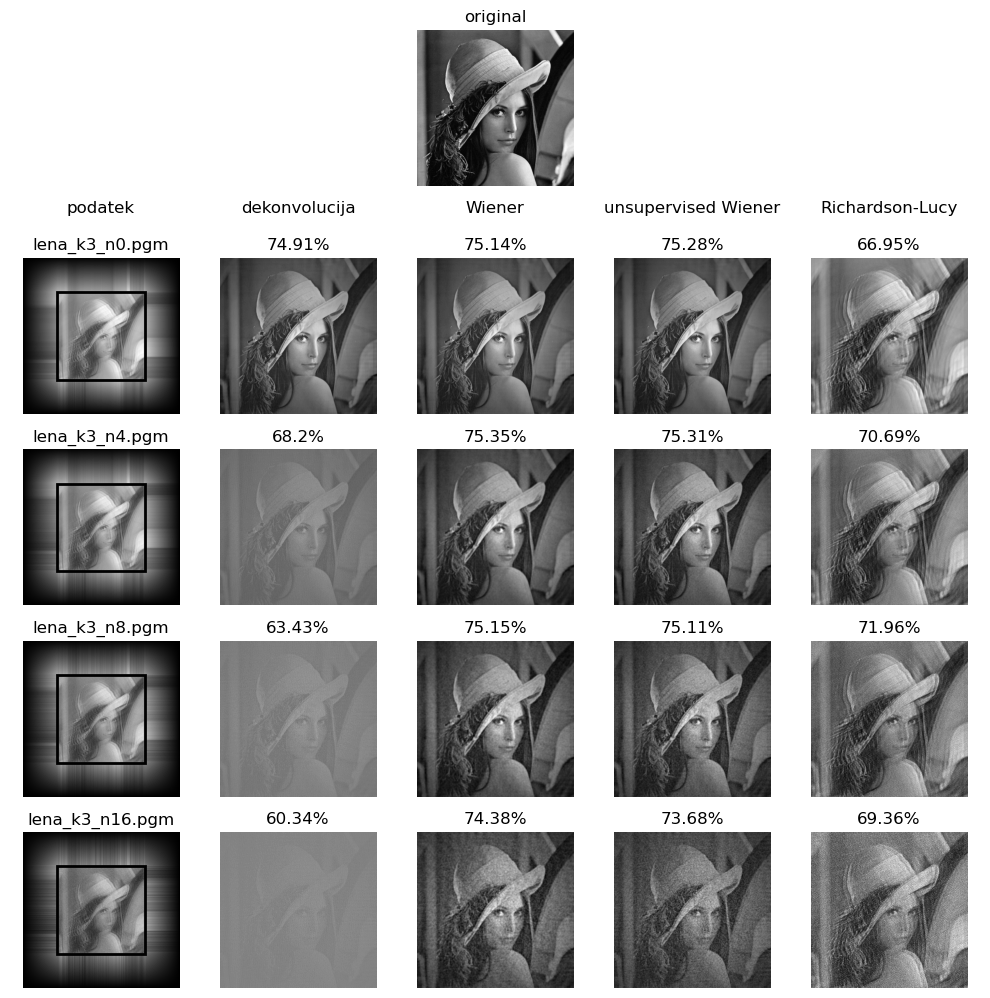

In [292]:
nr=5
nc=5
plt.figure(figsize=(nc*2,nr*2+2))
gs = plt.GridSpec(nrows=nr+2, ncols=nc, height_ratios=[1, 0.01]+[1 for _ in range(nr)])
plt.subplot(gs[2])
plt.axis('off')
plt.title('original')
img = mpimg.imread('podatki/lena_slike/The-famous-Lena-image-often-used-as-an-example-in-image-processing.png')
imgplot = plt.imshow(img)
column_titles = ['podatek', 'dekonvolucija', 'Wiener', 'unsupervised Wiener', 'Richardson-Lucy']
for i, title in enumerate(column_titles):
    plt.subplot(gs[i+5])
    plt.axis('off')
    plt.title(title)

n_kernel = '3'
šum = '0'
N_add = 200
n_iter = 50 #kernel1 in 2
n_iter = 10 #kernel3
razširitev = 'linear_ramp'
okno = 'triang'
noise = 10**6 #kernel1 in 2
noise = 1 #kernel3
vrstica = 2
primerjava_vse(n_kernel, šum, N_add, n_iter, razširitev, okno, vrstica, noise)

šum = '4'
noise = 10**6 #kernel1 in 3
#noise = 10**7 #kernel2
vrstica = 3
primerjava_vse(n_kernel, šum, N_add, n_iter, razširitev, okno, vrstica, noise)

šum = '8'
noise = 10**7 #kernel1
noise = 10**8 #kernel2
noise = 10**6 #kernel3
vrstica = 4
primerjava_vse(n_kernel, šum, N_add, n_iter, razširitev, okno, vrstica, noise)

šum = '16'
noise = 10**7 #kernel1
noise = 10**8 #kernel2
noise = 10**6 #kernel3
vrstica = 5
primerjava_vse(n_kernel, šum, N_add, n_iter, razširitev, okno, vrstica, noise)

plt.tight_layout()
#plt.savefig('slike/kernel'+str(n_kernel)+'_wiener_vse.pdf') #preveri za kernel 2 in 3
plt.show()

# periodična motnja

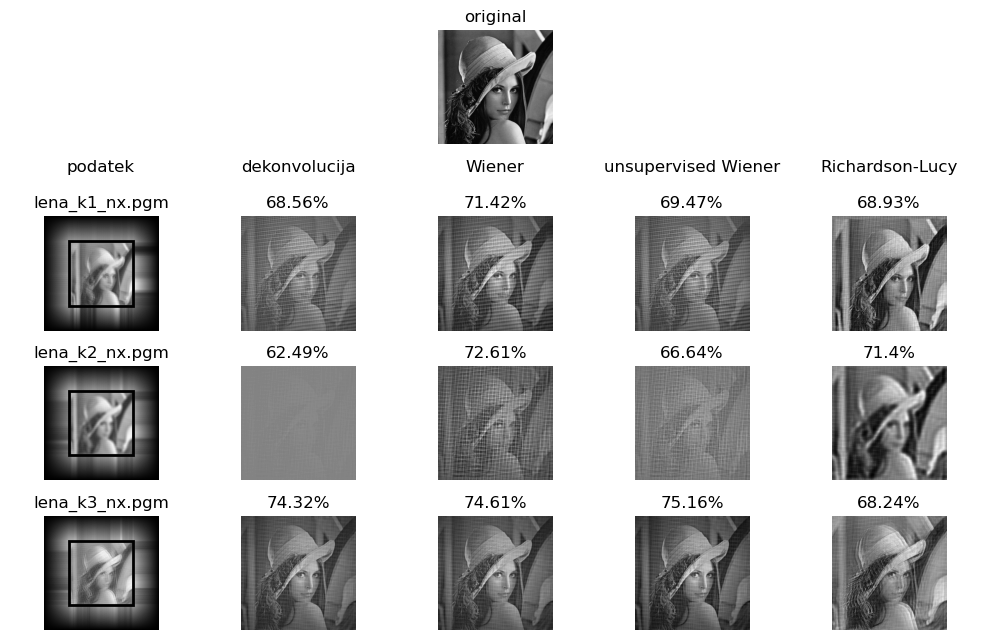

In [328]:
nr=4
nc=5
plt.figure(figsize=(nc*2,nr*2))
gs = plt.GridSpec(nrows=nr+2, ncols=nc, height_ratios=[1, 0.01]+[1 for _ in range(nr)])
plt.subplot(gs[2])
plt.axis('off')
plt.title('original')
img = mpimg.imread('podatki/lena_slike/The-famous-Lena-image-often-used-as-an-example-in-image-processing.png')
imgplot = plt.imshow(img)
column_titles = ['podatek', 'dekonvolucija', 'Wiener', 'unsupervised Wiener', 'Richardson-Lucy']
for i, title in enumerate(column_titles):
    plt.subplot(gs[i+5])
    plt.axis('off')
    plt.title(title)

n_kernel = '1'
šum = 'x'
N_add = 200
n_iter = 50
razširitev = 'linear_ramp'
okno = 'triang'
noise = 10**6 #kernel1 in 2
vrstica = 2
primerjava_vse(n_kernel, šum, N_add, n_iter, razširitev, okno, vrstica, noise)

n_kernel = '2'
noise = 10**6 #kernel1 in 2
vrstica = 3
primerjava_vse(n_kernel, šum, N_add, n_iter, razširitev, okno, vrstica, noise)

n_kernel ='3'
noise = 1 #kernel3
n_iter = 10 #kernel3
vrstica = 4
primerjava_vse(n_kernel, šum, N_add, n_iter, razširitev, okno, vrstica, noise)

plt.tight_layout()
#plt.savefig('slike/kernel_nx_vse.pdf')
plt.show()

In [319]:
datoteka = 'lena_k1_nx.pgm'
N_add = 200
kernel=kernel1
dim=512

data=np.loadtxt('podatki/lena_slike/'+datoteka,skiprows=3).reshape(dim,dim)
t = np.arange(0, dim)

data_resize=np.zeros(shape=(dim+2*N_add, dim+2*N_add))
data_resize[N_add:dim+N_add,N_add:dim+N_add] = data
kernel_resize = np.zeros(shape=(dim+2*N_add, dim+2*N_add))
kernel_resize[N_add:dim+N_add,N_add:dim+N_add] = kernel

data_resize = np.pad(data, ((N_add, N_add), (N_add, N_add)), mode='linear_ramp') #auto-padding!!

data = data_resize #razširitev slike
kernel = kernel_resize
okno = window('triang', data.shape)
signal_data=data*okno #okenske

signal_fft = np.fft.fft2(signal_data)
signal_freq = np.fft.fftfreq(dim)
signal_PSD = np.abs(data)**2

kernel_fft = np.fft.fft2(kernel)
kernel_PSD = np.abs(kernel_fft)**2
nonzero_rows = np.any(kernel != 0, axis=1)
nonzero_columns = np.any(kernel != 0, axis=0)
kernel_matrix = kernel[nonzero_rows][:, nonzero_columns]

deconvolved_fft = signal_fft / kernel_fft
deconvolved = np.fft.ifft2(deconvolved_fft)
deconvolved = np.fft.fftshift(deconvolved-np.min(deconvolved)) #remove negative
deconvolved = deconvolved/np.max(deconvolved)*255 #max is 255
deconvolved = deconvolved[N_add:-N_add, N_add:-N_add] #remove paddingg

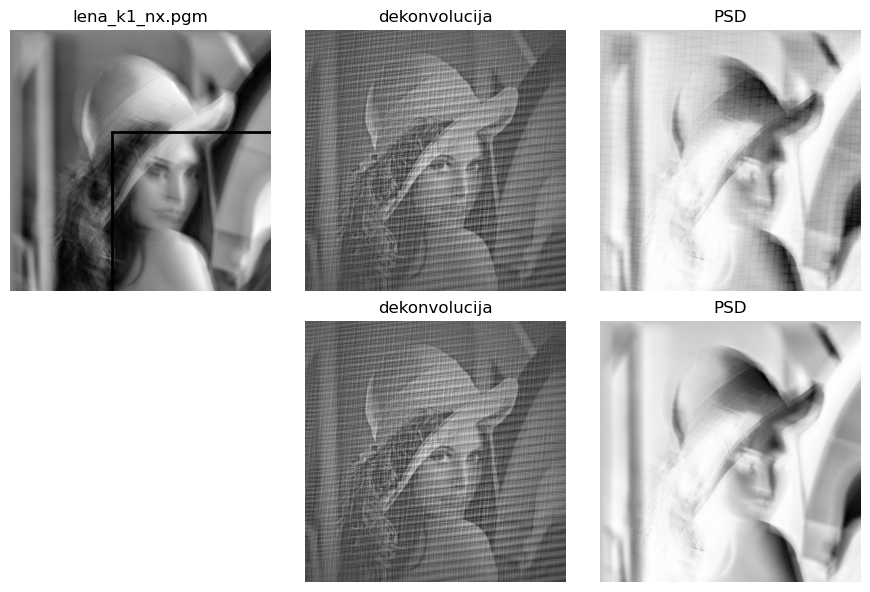

In [324]:
nr=2
nc=3
plt.figure(figsize=(nc*3,nr*3))
gs = plt.GridSpec(nrows=nr, ncols=nc)
plt.subplot(gs[0])
plt.axis('off')
plt.title(datoteka)
plt.imshow(data,cmap='gray')
plt.gca().add_patch(plt.Rectangle((N_add, N_add), dim, dim, linewidth=2, edgecolor='k', facecolor='none'))

plt.subplot(gs[1])
plt.axis('off')
plt.title('dekonvolucija')
plt.imshow(deconvolved.real,cmap='gray')

data=np.loadtxt('podatki/lena_slike/lena_k1_nx.pgm',skiprows=3).reshape(dim,dim)
signal_fft = np.fft.fft2(data)
signal_PSD = np.abs(data)**2
plt.subplot(gs[2])
plt.axis('off')
plt.title('PSD')
plt.imshow((signal_PSD), cmap='Grays')

_, deconvolved = lena(n_kernel='1',šum='x',N_add=200,razširitev='linear_ramp',okno='triang')
plt.subplot(gs[4])
plt.axis('off')
plt.title('dekonvolucija')
plt.imshow(deconvolved.real,cmap='gray')

data=np.loadtxt('podatki/lena_slike/lena_k1_n0.pgm',skiprows=3).reshape(dim,dim)
signal_fft = np.fft.fft2(data)
signal_PSD = np.abs(data)**2
plt.subplot(gs[5])
plt.axis('off')
plt.title('PSD')
plt.imshow((signal_PSD), cmap='Grays')

plt.tight_layout()